# 01 - Exploratory data analysis

Understanding the synthetic service-desk dataset before modeling SLA breaches. Part 1 covers the shape and quality of the data, distributions, time patterns, and the label.

The data is simulated (see [docs/dataset_design.md](../docs/dataset_design.md)), so the goal is to check that it behaves as designed and to learn what a model will face, not to discover facts about a real organization.

**To run:** start the database (`docker compose up -d`), load it (`python -m opspilot.db.load`), then run all cells from the top. Charts are saved to `reports/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

from opspilot.analysis.data import load_tickets, read_sql
from opspilot.analysis.stats import wilson_interval
from opspilot.db.connection import connect

ROOT = Path.cwd().parent  # this notebook lives one level below the repository root
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
})
ACCENT, MUTED, HIGHLIGHT = "#2f6690", "#9aa5b1", "#d1495b"


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")


def rate_with_interval(breached: pd.Series) -> pd.Series:
    """Breach rate and 95% Wilson interval for a boolean series."""
    low, high = wilson_interval(int(breached.sum()), len(breached))
    return pd.Series({"n": len(breached), "rate": breached.mean(), "low": low, "high": high})

In [2]:
with connect() as conn:
    tickets = load_tickets(conn)
    calendar = read_sql(conn, "SELECT * FROM calendar_days ORDER BY day")
calendar["day"] = pd.to_datetime(calendar["day"])

resolved = tickets[tickets["status"] == "resolved"].copy()
resolved["sla_breached"] = resolved["sla_breached"].astype(bool)  # no missing values once filtered
print(f"{len(tickets):,} tickets, {len(resolved):,} resolved, {tickets['created_at'].min():%Y-%m-%d} to {tickets['created_at'].max():%Y-%m-%d}")

50,295 tickets, 49,242 resolved, 2024-01-01 to 2025-12-31


## 1. Shape and quality

In [3]:
pd.DataFrame({
    "dtype": tickets.dtypes.astype(str),
    "missing": tickets.isna().sum(),
    "missing_pct": (100 * tickets.isna().mean()).round(1),
    "distinct": tickets.nunique(),
})

,dtype,missing,missing_pct,distinct
ticket_id,str,0,0.0,50295
created_at,datetime64[us],0,0.0,50251
channel,str,0,0.0,5
requester_type,str,0,0.0,3
department,str,0,0.0,10
category,str,0,0.0,8
subcategory,str,0,0.0,29
ticket_type,str,0,0.0,2
priority,str,0,0.0,4
assigned_team,str,0,0.0,7


Creation-time fields have no missing values. The outcome columns are missing for 1,053 tickets (2.1%), the unresolved and cancelled ones, and `satisfaction_score` is missing for 72.3% because most requesters do not answer the survey.

Two smaller things worth knowing:

- `created_at` has 50,251 distinct values for 50,295 tickets, so a few tickets share a timestamp to the second. That is why the SQL backlog calculation needed an explicit tie-breaker.
- `description` has only 9,903 distinct values. The text comes from templates, which will make text features look more useful here than they would on real tickets.

In [4]:
# Missing outcomes should depend only on status: present for resolved tickets, absent otherwise.
outcome_columns = ["resolved_at", "resolution_hours", "resolved_by_team", "sla_breached", "satisfaction_score"]
tickets[outcome_columns].isna().groupby(tickets["status"]).mean().round(3)

,resolved_at,resolution_hours,resolved_by_team,sla_breached,satisfaction_score
status,,,,,
cancelled,1.0,1.0,1.0,1.0,1.000
in_progress,1.0,1.0,1.0,1.0,1.000
open,1.0,1.0,1.0,1.0,1.000
resolved,0.0,0.0,0.0,0.0,0.717


Missing values follow the design exactly: every outcome column is present for resolved tickets and absent for the rest. The only partly missing column is `satisfaction_score`, absent for 71.7% of resolved tickets.

None of this is random. A value is missing because of a ticket's status or because someone chose not to answer the survey, so it should never be filled in with an average.

## 2. Distributions

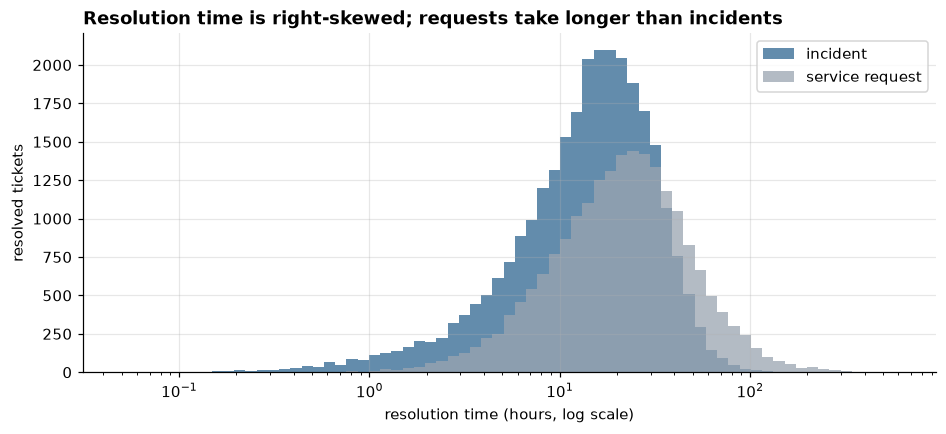

In [5]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(0.05), np.log10(resolved["resolution_hours"].max()), 70)
for ticket_type, color in [("incident", ACCENT), ("service_request", MUTED)]:
    hours = resolved.loc[resolved["ticket_type"] == ticket_type, "resolution_hours"]
    ax.hist(hours, bins=bins, color=color, alpha=0.75, label=ticket_type.replace("_", " "))
ax.set_xscale("log")
ax.set_xlabel("resolution time (hours, log scale)")
ax.set_ylabel("resolved tickets")
ax.set_title("Resolution time is right-skewed; requests take longer than incidents")
ax.legend()
save(fig, "01_resolution_hours")

In [6]:
summary = resolved.groupby("ticket_type")["resolution_hours"].describe(percentiles=[0.5, 0.9, 0.99])
summary["mean_over_median"] = summary["mean"] / summary["50%"]
print(f"skewness: hours {resolved['resolution_hours'].skew():.2f}, log hours {np.log(resolved['resolution_hours']).skew():.2f}")
summary.round(1)

skewness: hours 4.50, log hours -0.78


,count,mean,std,min,50%,90%,99%,max,mean_over_median
ticket_type,,,,,,,,,
incident,28525.0,17.7,13.2,0.1,15.1,34.4,60.3,196.3,1.2
service_request,20717.0,28.8,27.9,0.2,21.5,56.7,137.6,590.6,1.3


Resolution time is strongly right-skewed (skewness 4.5). On a log scale it is much closer to symmetric (-0.78); the remaining left tail is fast work such as password resets.

Service requests take longer than incidents (median 21.5 against 15.1 hours) and have a much longer tail (99th percentile 137.6 against 60.3 hours). Medians are the right summary for this shape, and a future resolution-time model would be better off predicting log hours.

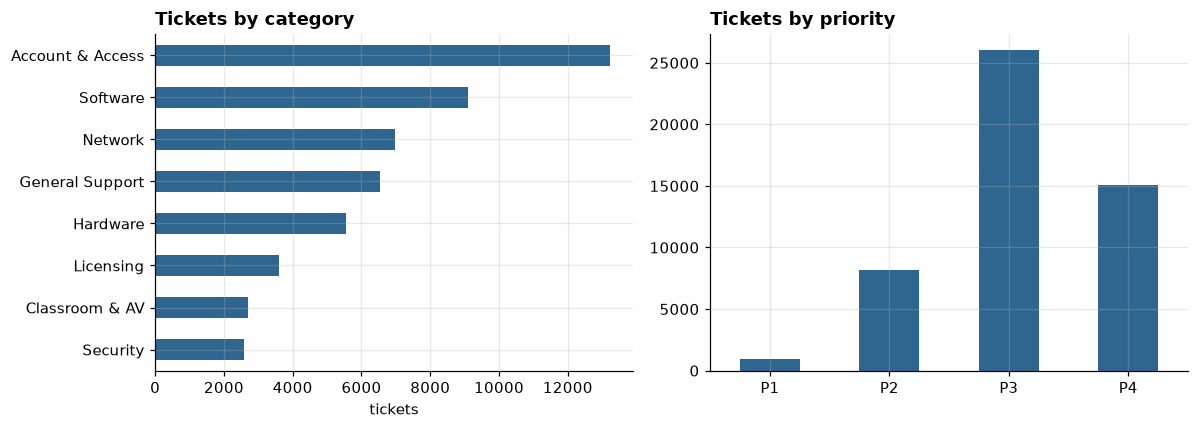

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
tickets["category"].value_counts().sort_values().plot.barh(ax=axes[0], color=ACCENT)
axes[0].set_title("Tickets by category")
axes[0].set_xlabel("tickets")
axes[0].set_ylabel("")
tickets["priority"].value_counts().sort_index().plot.bar(ax=axes[1], color=ACCENT, rot=0)
axes[1].set_title("Tickets by priority")
axes[1].set_xlabel("")
fig.tight_layout()
save(fig, "01_category_priority")

Account & Access is the largest category, mostly password resets. P3 is the most common priority, and P1 is rare: under 1,000 tickets in two years, so any estimate for P1 alone carries wide uncertainty.

## 3. Time patterns

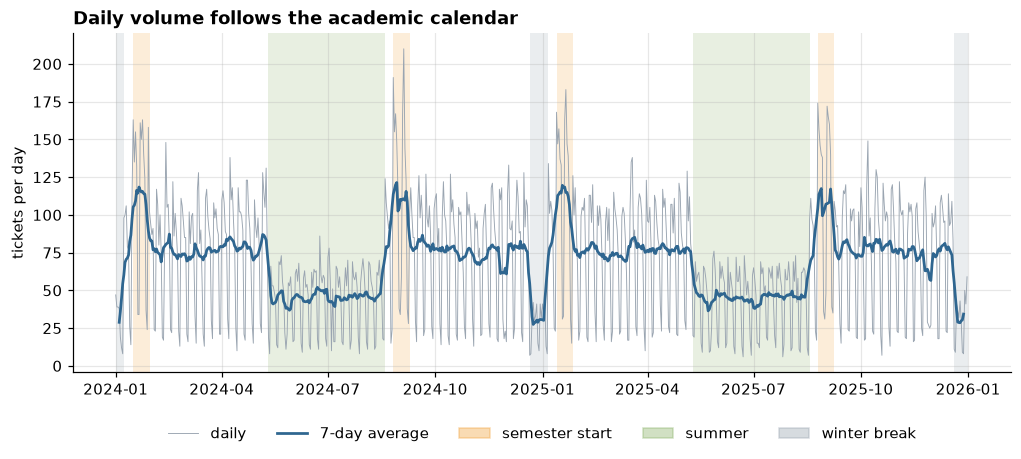

In [8]:
daily = tickets.groupby(tickets["created_at"].dt.normalize()).size()

fig, ax = plt.subplots(figsize=(11, 4))
period_colors = {"semester_start": "#f2a541", "summer": "#8cb369", "winter_break": MUTED}
for period, color in period_colors.items():
    for day in calendar.loc[calendar["academic_period"] == period, "day"]:
        ax.axvspan(day, day + pd.Timedelta(days=1), color=color, alpha=0.2, lw=0)
ax.plot(daily.index, daily, color=MUTED, lw=0.6)
ax.plot(daily.index, daily.rolling(7, center=True).mean(), color=ACCENT, lw=1.8)
ax.set_ylabel("tickets per day")
ax.set_title("Daily volume follows the academic calendar")
handles = [plt.Line2D([], [], color=MUTED, lw=0.6, label="daily"),
           plt.Line2D([], [], color=ACCENT, lw=1.8, label="7-day average")]
handles += [Patch(color=c, alpha=0.4, label=p.replace("_", " ")) for p, c in period_colors.items()]
ax.legend(handles=handles, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
save(fig, "01_daily_volume")

In [9]:
print("busiest days:")
daily.sort_values(ascending=False).head(5)

busiest days:


created_at
2024-09-04    210
2024-08-26    191
2025-01-21    183
2025-08-25    174
2025-09-02    172
dtype: int64

Two academic years are clearly visible. Daily volume roughly doubles from summer (about 45 tickets a day) to semester starts (about 115), and falls to about 30 over winter break. The regular dips are weekends.

The busiest day, 2024-09-04 with 210 tickets, combines a semester start with the lecture-capture incident.

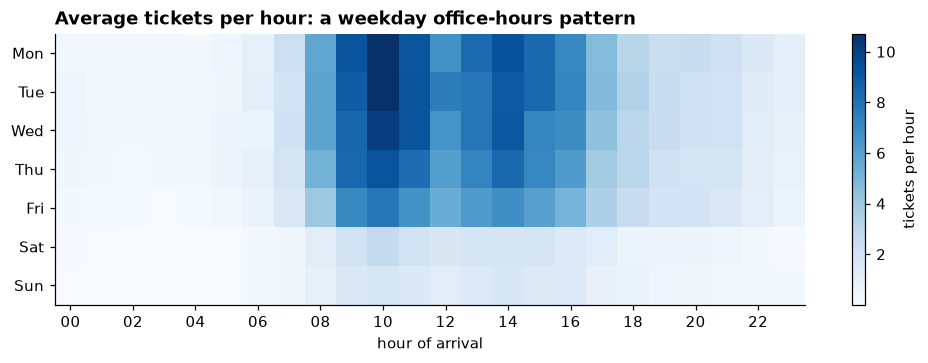

In [10]:
# Average tickets in each weekday-hour slot (each weekday occurs about 104 times).
weekday_counts = calendar["day_of_week"].value_counts().sort_index().to_numpy()
slots = tickets.groupby([tickets["created_at"].dt.dayofweek, tickets["created_at"].dt.hour]).size().unstack(fill_value=0)
per_slot = slots.div(weekday_counts, axis=0)

fig, ax = plt.subplots(figsize=(11, 3.2))
image = ax.imshow(per_slot, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("hour of arrival")
ax.grid(False)
ax.set_title("Average tickets per hour: a weekday office-hours pattern")
fig.colorbar(image, ax=ax, label="tickets per hour")
save(fig, "01_hour_weekday_heatmap")

Volume peaks at 10:00 on Monday to Wednesday at about 10 tickets an hour, with a second, smaller peak after lunch, and tails off through the week. Weekends carry a small fraction of weekday volume. The 08:00-18:00 staffed hours cover most demand but not the evening tail.

created_at,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
n,210.0,136.0,109.0,127.0,131.0,240.0,454.0,1084.0,2956.0,4696.0,...,4714.0,4119.0,3627.0,2384.0,1679.0,1285.0,1177.0,1056.0,690.0,464.0
rate,23.8,26.5,23.9,22.8,20.6,10.8,12.8,11.0,10.3,10.5,...,13.4,13.3,16.2,16.8,40.6,37.7,38.1,37.7,32.5,27.2
low,18.6,19.8,16.8,16.4,14.6,7.5,10.0,9.3,9.3,9.7,...,12.5,12.3,15.1,15.3,38.3,35.1,35.4,34.8,29.1,23.3
high,30.0,34.5,32.7,30.9,28.3,15.4,16.2,13.0,11.5,11.5,...,14.5,14.4,17.5,18.3,43.0,40.4,41.0,40.7,36.0,31.4


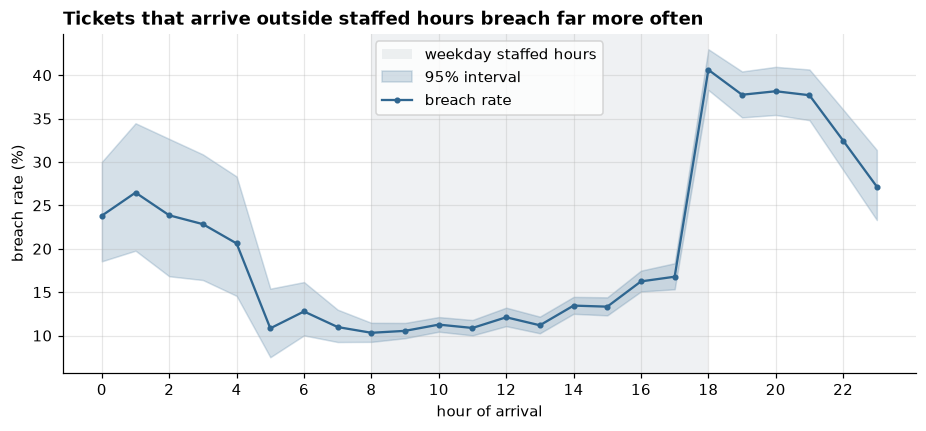

In [11]:
by_hour = resolved.groupby(resolved["created_at"].dt.hour)["sla_breached"].apply(rate_with_interval).unstack()

fig, ax = plt.subplots()
ax.axvspan(8, 17.99, color=MUTED, alpha=0.15, lw=0, label="weekday staffed hours")
ax.fill_between(by_hour.index, 100 * by_hour["low"], 100 * by_hour["high"], color=ACCENT, alpha=0.2, label="95% interval")
ax.plot(by_hour.index, 100 * by_hour["rate"], color=ACCENT, marker="o", ms=3, label="breach rate")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of arrival")
ax.set_ylabel("breach rate (%)")
ax.set_title("Tickets that arrive outside staffed hours breach far more often")
ax.legend(loc="upper center")
save(fig, "01_breach_by_hour")
by_hour.assign(rate=lambda d: (100 * d["rate"]).round(1), low=lambda d: (100 * d["low"]).round(1),
               high=lambda d: (100 * d["high"]).round(1)).astype({"n": int}).T

This is the strongest pattern in part 1.

- Tickets arriving between 08:00 and 17:00 breach 10-17% of the time.
- At 18:00 the rate jumps to 40.6% and stays near 38% until 21:00. Evening arrivals wait the whole night for the desk to open.
- Tickets arriving between midnight and 04:00 do better (21-27%) because their wait is shorter, and from 05:00 the rate is back near daytime levels.
- During the day the rate climbs from 10.3% at 08:00 to 16.8% at 17:00, consistent with the queue building up.

The night-time intervals are wide because only 109-240 tickets arrived in each of those hours over two years. The `hours_until_staffed` feature in the feature view is designed to capture this effect directly.

## 4. The label: `sla_breached`

In [12]:
base_rate = resolved["sla_breached"].mean()
breaches = int(resolved["sla_breached"].sum())
print(f"breach rate: {base_rate:.1%} ({breaches:,} of {len(resolved):,} resolved tickets)")
print(f"always predicting 'no breach' would be {1 - base_rate:.1%} accurate and find 0 of {breaches:,} breaches")

breach rate: 15.7% (7,732 of 49,242 resolved tickets)
always predicting 'no breach' would be 84.3% accurate and find 0 of 7,732 breaches


15.7% of resolved tickets breached. That imbalance decides how a model has to be evaluated: one that never predicts a breach is 84.3% accurate and finds nothing. Phase 5 will use precision, recall, F1 and ROC-AUC, and choose a decision threshold based on how many tickets a team can realistically act on.

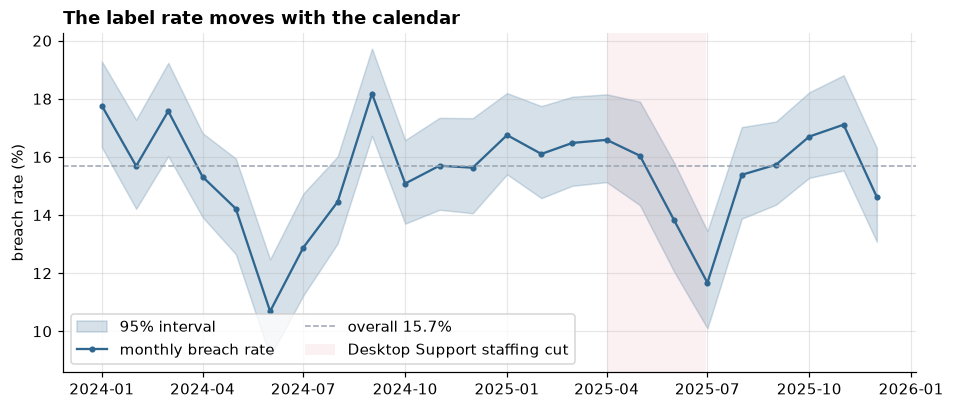

In [13]:
monthly = resolved.groupby(resolved["created_at"].dt.to_period("M"))["sla_breached"].apply(rate_with_interval).unstack()
months = monthly.index.to_timestamp()

fig, ax = plt.subplots()
ax.fill_between(months, 100 * monthly["low"], 100 * monthly["high"], color=ACCENT, alpha=0.2, label="95% interval")
ax.plot(months, 100 * monthly["rate"], color=ACCENT, marker="o", ms=3, label="monthly breach rate")
ax.axhline(100 * base_rate, color=MUTED, ls="--", lw=1, label=f"overall {base_rate:.1%}")
ax.axvspan(pd.Timestamp("2025-04-01"), pd.Timestamp("2025-06-30"), color=HIGHLIGHT, alpha=0.08, lw=0,
           label="Desktop Support staffing cut")
ax.set_ylabel("breach rate (%)")
ax.set_title("The label rate moves with the calendar")
ax.legend(loc="lower left", ncol=2)
save(fig, "01_monthly_breach_rate")

The breach rate ranges from 10.7% (June 2024) to 18.2% (September 2024) and follows the calendar: lowest in summer, highest around semester starts. For modeling, this means:

- The label rate is not constant over time, so a time-based train/test split will see different base rates.
- Month or academic period carries information about risk.

The chart also shows what it cannot show. The Desktop Support staffing cut (shaded) is hard to see in the overall rate, which falls through that quarter as summer begins. Only a comparison with the same months of 2024 hints at it (16.6%, 16.0% and 13.8% in April-June 2025 against 15.3%, 14.2% and 10.7%). The team-level, year-over-year comparison in Phase 3 shows it clearly. An overall metric can hide a change in one part of the operation.

In [14]:
# Outcomes near the snapshot: recent tickets may not have a label yet.
recent = tickets[tickets["created_at"] >= pd.Timestamp("2025-12-18")]
print(f"tickets created in the final 14 days: {len(recent):,}")
recent["status"].value_counts()

tickets created in the final 14 days: 562


status
resolved       502
open            34
cancelled       15
in_progress     11
Name: count, dtype: int64

Of the 562 tickets created in the final 14 days, 45 are still open or in progress at the snapshot and 15 were cancelled. The unresolved ones are, by definition, the slow ones, so keeping the final weeks with only their resolved tickets would bias the label toward fast, on-time tickets. As the design document specifies, modeling data will stop at 2025-12-17.

## Part 1 summary

| Finding | Consequence for modeling |
|---|---|
| Missing values are structural (status, survey non-response) | Never impute outcomes; train only on resolved tickets |
| Resolution time is right-skewed | Use medians; model log hours if predicting duration |
| Arrival hour has a large effect (about 11% in the morning, about 40% in the early evening) | Keep `hours_until_staffed` and `hour_of_day` |
| The label is imbalanced (15.7%) | Evaluate with precision, recall, F1 and ROC-AUC, not accuracy |
| The label rate moves with the calendar | Use a time-based split and expect a different base rate in test |
| Team-level changes can be hidden in overall rates | Check performance by team, not only overall |
| Recent tickets lack outcomes | Stop modeling data at 2025-12-17 |

Part 2 looks at relationships between variables: department confounding, interactions, and which differences are large enough to matter.

# Part 2 - Relationships

Part 1 described variables one at a time. Part 2 asks how they relate to breaches and to each other: which apparent effects are really effects of something else, which combine, and which are large enough to matter.

Part 2 uses the `ticket_features` view, which holds only information known when each ticket was created, restricted to tickets with a label.

In [15]:
from scipy.stats import chi2_contingency

from opspilot.analysis.data import load_features
from opspilot.analysis.stats import cramers_v, difference_interval, standardized_rates

with connect() as conn:
    features = load_features(conn)
    subcategories = read_sql(conn, "SELECT * FROM subcategories")

labelled = features[features["sla_breached"].notna()].copy()
labelled["sla_breached"] = labelled["sla_breached"].astype(bool)

reduced_staffing = (labelled["is_weekend"] | labelled["is_holiday"]).astype(bool)
labelled["arrival_window"] = np.select(
    [reduced_staffing, labelled["hour_of_day"].between(8, 17)],
    ["weekend_or_holiday", "weekday_staffed"],
    "weekday_after_hours",
)
print(f"{len(labelled):,} labelled tickets")

49,242 labelled tickets


## 5. Is department a cause or a proxy?

Departments differ in breach rate, but they also differ in what they ask for. Direct standardization asks: what would each department's breach rate be if it had the same mix of issues as the data overall? If the gaps shrink after adjustment, the mix explains them.

In [16]:
crude = labelled.groupby("department")["sla_breached"].apply(rate_with_interval).unstack()
by_category = standardized_rates(labelled, "department", "category", "sla_breached")
by_subcategory = standardized_rates(labelled, "department", "subcategory", "sla_breached")

departments = pd.DataFrame({
    "resolved": crude["n"].astype(int),
    "crude_pct": 100 * crude["rate"],
    "crude_low": 100 * crude["low"],
    "crude_high": 100 * crude["high"],
    "adjusted_for_category_pct": 100 * by_category["adjusted_rate"],
    "adjusted_for_subcategory_pct": 100 * by_subcategory["adjusted_rate"],
}).sort_values("crude_pct")

spread = departments[["crude_pct", "adjusted_for_category_pct", "adjusted_for_subcategory_pct"]].agg(lambda c: c.max() - c.min())
print("gap between highest and lowest department (points):")
print(spread.round(1).to_string())
departments.round(1)

gap between highest and lowest department (points):
crude_pct                       3.1
adjusted_for_category_pct       1.2
adjusted_for_subcategory_pct    1.2


,resolved,crude_pct,crude_low,crude_high,adjusted_for_category_pct,adjusted_for_subcategory_pct
department,,,,,,
Business School,6524,15.0,14.2,15.9,15.4,15.2
Engineering,10583,15.1,14.4,15.8,15.5,15.6
Arts & Sciences,12807,15.2,14.6,15.9,15.6,15.7
Health Sciences,5629,16.1,15.1,17.0,16.1,16.0
Finance,2355,16.3,14.9,17.9,15.3,15.4
Library,2788,16.5,15.2,17.9,16.5,16.4
Admissions,1963,16.6,15.0,18.3,15.4,15.4
Human Resources,1779,16.7,15.0,18.5,16.1,16.1
Student Services,2757,16.8,15.4,18.2,15.8,15.9


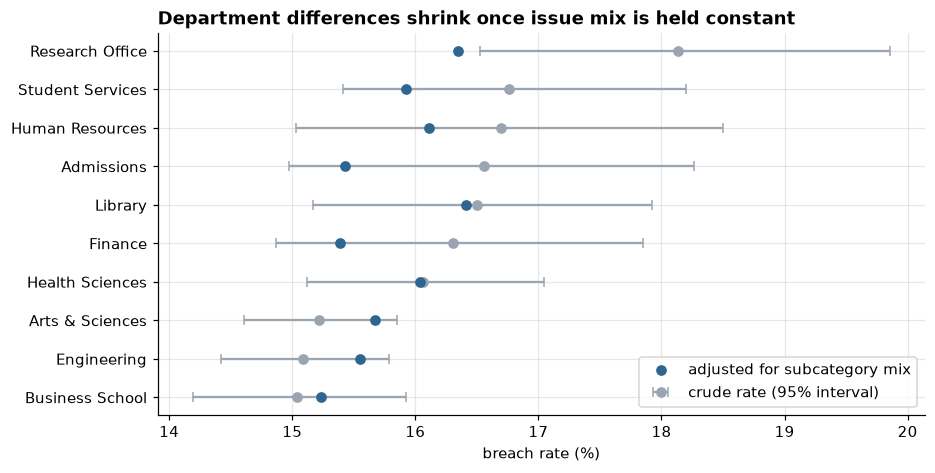

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(departments))
ax.errorbar(departments["crude_pct"], y,
            xerr=[departments["crude_pct"] - departments["crude_low"], departments["crude_high"] - departments["crude_pct"]],
            fmt="o", color=MUTED, capsize=3, label="crude rate (95% interval)")
ax.scatter(departments["adjusted_for_subcategory_pct"], y, color=ACCENT, zorder=3, label="adjusted for subcategory mix")
ax.set_yticks(y, departments.index)
ax.set_xlabel("breach rate (%)")
ax.set_title("Department differences shrink once issue mix is held constant")
ax.legend(loc="lower right")
save(fig, "01_department_standardized")

In [18]:
# Why: departments submit very different mixes of issues, and issues differ in risk.
mix = pd.crosstab(labelled["department"], labelled["category"], normalize="index").loc[departments.index]
category_risk = labelled.groupby("category")["sla_breached"].mean().sort_values()
(100 * mix[category_risk.index]).round(0).astype(int).assign(
    expected_from_mix_pct=lambda d: (d @ category_risk.values).round(1))

category,General Support,Account & Access,Security,Licensing,Classroom & AV,Software,Network,Hardware,expected_from_mix_pct
department,,,,,,,,,
Business School,14,29,5,6,5,15,16,10,15.3
Engineering,14,30,4,6,6,15,16,10,15.4
Arts & Sciences,13,28,4,6,7,15,16,10,15.4
Health Sciences,13,27,5,7,7,17,14,10,15.5
Finance,12,18,7,11,2,26,9,15,16.8
Library,13,26,5,8,4,19,13,11,15.5
Admissions,11,18,7,10,2,28,9,15,17.0
Human Resources,12,18,7,9,2,27,9,16,16.9
Student Services,12,18,7,10,2,27,9,14,16.6


Crude breach rates span 3.1 points across departments, from 15.0% (Business School) to 18.1% (Research Office). Holding the issue mix constant shrinks the spread to 1.2 points, and that remainder is within sampling noise: every department's crude interval overlaps the others.

The mix table shows why. Finance, Admissions, Human Resources, Student Services and the Research Office submit more Software and Hardware tickets and fewer password resets than the academic units, and those categories breach more often. From their mix alone they would be expected to breach 16.6-17.3% of the time, against 15.3-15.5% for the academic units.

Department looks predictive because it stands in for what a department asks for. That matches how the data was generated, where department has no direct effect. For modeling, department is unlikely to add much once category and subcategory are features, and any importance a model gives it should be read with this in mind. With real data, this check would come before any claim that a department is underserved.

## 6. Interactions

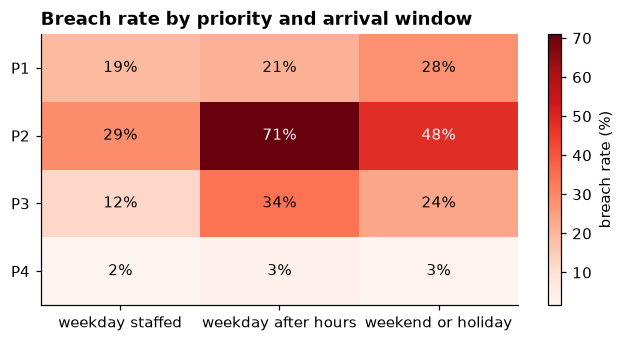

In [19]:
window_order = ["weekday_staffed", "weekday_after_hours", "weekend_or_holiday"]
by_priority_window = labelled.pivot_table(index="priority", columns="arrival_window", values="sla_breached",
                                          aggfunc="mean")[window_order]

fig, ax = plt.subplots(figsize=(7, 3.2))
image = ax.imshow(100 * by_priority_window, cmap="Reds", aspect="auto")
for (row, col), value in np.ndenumerate(100 * by_priority_window.to_numpy()):
    ax.text(col, row, f"{value:.0f}%", ha="center", va="center", color="white" if value > 45 else "black")
ax.set_xticks(range(3), [w.replace("_", " ") for w in window_order])
ax.set_yticks(range(4), by_priority_window.index)
ax.grid(False)
ax.set_title("Breach rate by priority and arrival window")
fig.colorbar(image, ax=ax, label="breach rate (%)")
save(fig, "01_priority_by_window")

Priority and arrival window do not simply add up:

- **P2** goes from 29% in staffed hours to 71% after hours (+42 points). Its 8-hour target is mostly gone by the time the desk opens.
- **P3** goes from 12% to 34% (+22 points).
- **P4** barely moves (2% to 3%) because a 72-120 hour target absorbs a night's wait.
- **P1** moves least of the urgent priorities on weekday evenings (19% to 21%) because on-call staff start it straight away, but rises to 28% at weekends.

A model with only additive terms, such as a plain logistic regression, cannot represent this without an explicit interaction term, while tree-based models pick it up naturally. That is a concrete reason to compare both kinds of model in Phase 5.

open_per_agent_bucket,0-1,1-2,2-4,4-6,6+
assigned_team,,,,,
Classroom Technology,11.7,16.8,24.8,NaN,NaN
Desktop Support,11.3,15.8,20.7,31.5,NaN
Enterprise Applications,12.9,17.7,24.4,32.1,NaN
Identity & Access,6.4,8.6,11.6,16.7,19.8
Network Operations,11.8,16.0,22.4,32.4,43.4
Security Operations,12.8,14.4,16.4,NaN,NaN
Service Desk,2.3,3.4,3.7,4.7,6.2


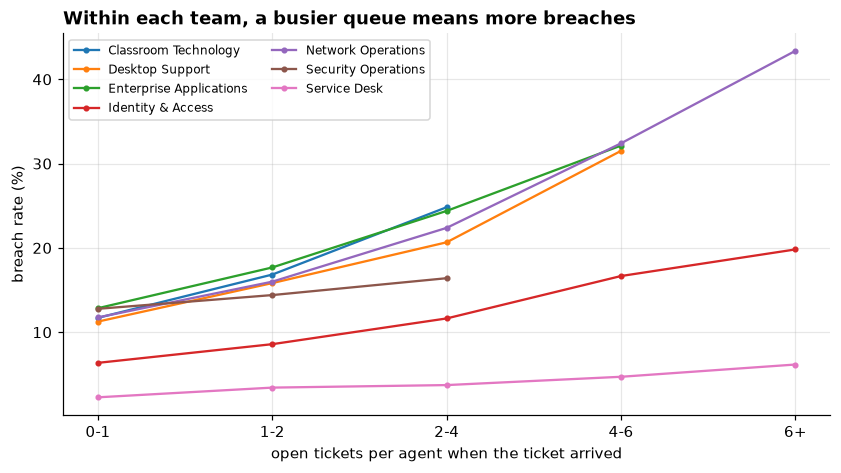

In [20]:
bucket_labels = ["0-1", "1-2", "2-4", "4-6", "6+"]
labelled["open_per_agent_bucket"] = pd.cut(labelled["team_open_per_agent"], [0, 1, 2, 4, 6, np.inf],
                                           right=False, labels=bucket_labels)
grouped = labelled.groupby(["assigned_team", "open_per_agent_bucket"], observed=True)["sla_breached"]
within_team = grouped.mean().unstack()
counts = grouped.size().unstack()
within_team = within_team.where(counts >= 100)  # hide cells with too few tickets to read

fig, ax = plt.subplots(figsize=(9, 4.5))
for team, row in within_team.iterrows():
    ax.plot(bucket_labels, 100 * row.reindex(bucket_labels), marker="o", ms=3, label=team)
ax.set_xlabel("open tickets per agent when the ticket arrived")
ax.set_ylabel("breach rate (%)")
ax.set_title("Within each team, a busier queue means more breaches")
ax.legend(fontsize=8, ncol=2)
save(fig, "01_workload_within_team")
(100 * within_team).round(1)

The workload effect appears inside every team, not only between busy and quiet teams. Network Operations goes from 11.8% with under one open ticket per agent to 43.4% at six or more.

The slope differs by team. It is steep for teams with tight incident targets (Network Operations, Enterprise Applications, Classroom Technology) and shallow for Service Desk (2.3% to 6.2%), whose work is quick and has long targets. Security Operations rarely reaches high load except during the phishing campaign, so its upper buckets have fewer than 100 tickets and are hidden. A slope that varies by team is another interaction (team x load) for the model comparison.

## 7. Significance versus size

With about 49,000 labelled tickets, almost any difference is statistically significant. The p-value says whether an association is distinguishable from zero; Cramer's V (0 = none, 1 = perfect) says how strong it is.

In [21]:
rows = []
for column in ["priority", "category", "assigned_team", "arrival_window", "academic_period",
               "requester_type", "department", "channel"]:
    table = pd.crosstab(labelled[column], labelled["sla_breached"])
    chi_square, p_value, dof, _ = chi2_contingency(table, correction=False)
    rows.append({"variable": column, "levels": len(table), "chi_square": round(chi_square, 1),
                 "p_value": f"{p_value:.1e}", "cramers_v": round(cramers_v(table), 3)})
pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)

,variable,levels,chi_square,p_value,cramers_v
0,priority,4,4922.3,0.0e+00,0.316
1,category,8,2198.8,0.0e+00,0.211
2,assigned_team,7,2145.8,0.0e+00,0.209
3,arrival_window,3,1888.9,0.0e+00,0.196
4,academic_period,4,161.3,9.7e-35,0.057
5,requester_type,3,62.8,2.3e-14,0.036
6,channel,5,49.9,3.8e-10,0.032
7,department,10,23.9,4.5e-03,0.022


In [22]:
# The same association measured on samples of different sizes: the p-value
# depends heavily on n, Cramer's V barely moves.
rng = np.random.default_rng(0)
rows = []
for n in [500, 2_000, 10_000, len(labelled)]:
    sample = labelled.iloc[rng.choice(len(labelled), size=n, replace=False)]
    table = pd.crosstab(sample["channel"], sample["sla_breached"])
    rows.append({"sample_size": n, "p_value": f"{chi2_contingency(table, correction=False)[1]:.1e}",
                 "cramers_v": round(cramers_v(table), 3)})
pd.DataFrame(rows)

,sample_size,p_value,cramers_v
0,500,3.4e-02,0.144
1,2000,2.6e-01,0.052
2,10000,2.3e-02,0.034
3,49242,3.8e-10,0.032


Every variable's association with breaching is statistically significant (the largest p-value is 0.0045, for department), so p-values cannot rank them. Cramer's V can:

- **Priority** (0.32) is the strongest single association.
- **Category, team and arrival window** follow at about 0.20 each.
- **Academic period, requester type, channel and department** are all below 0.06: real, but small.

On its own, department's p-value of 0.0045 would look like a finding. Section 5 shows it is mostly issue mix.

The sampling table shows the mechanism. As the sample grows from 2,000 to 49,242 tickets, the p-value for channel falls from 0.26 to 4e-10 while Cramer's V settles near 0.03. The 500-ticket sample shows the opposite risk: p = 0.03 and V = 0.14, a chance result that overstates the true association several times over (Cramer's V is biased upward in small samples). An effect size with an interval says more than a p-value alone.

## 8. Intervals for the Phase 3 comparisons

[docs/sql_analysis.md](../docs/sql_analysis.md) quotes confidence intervals that were computed with a one-off script. They are recomputed here with the tested `difference_interval` helper and saved to `reports/stats/phase3_intervals.csv`, so every interval in that document can be reproduced.

In [23]:
r = resolved.merge(subcategories[["subcategory", "owning_team"]], on="subcategory")
r["day"] = r["created_at"].dt.normalize()
r = r.merge(calendar[["day", "is_weekend", "is_holiday", "academic_period"]], on="day")
r["quarter"] = r["created_at"].dt.to_period("Q").astype(str)
weekday_hours = ~(r["is_weekend"] | r["is_holiday"]).astype(bool)
staffed_hour = r["created_at"].dt.hour.between(8, 17)
team = r["resolved_by_team"]
phishing_days = r["day"].between("2025-03-18", "2025-03-20")


def compare(label, group_a, group_b):
    breached = r["sla_breached"]
    difference, low, high = difference_interval(int(breached[group_a].sum()), int(group_a.sum()),
                                                int(breached[group_b].sum()), int(group_b.sum()))
    return {"comparison": label,
            "rate_a_pct": 100 * breached[group_a].mean(), "n_a": int(group_a.sum()),
            "rate_b_pct": 100 * breached[group_b].mean(), "n_b": int(group_b.sum()),
            "difference_pts": 100 * difference, "low_pts": 100 * low, "high_pts": 100 * high}


def year_over_year(team_name, quarter, exclude=None):
    year, q = quarter.split("Q")
    earlier = f"{int(year) - 1}Q{q}"
    keep = ~exclude if exclude is not None else pd.Series(True, index=r.index)
    return compare(f"{team_name}, {quarter} vs {earlier}" + (" (excluding phishing days)" if exclude is not None else ""),
                   (team == team_name) & (r["quarter"] == quarter) & keep,
                   (team == team_name) & (r["quarter"] == earlier))


intervals = pd.DataFrame([
    compare("P2: weekday after hours vs weekday staffed",
            (r["priority"] == "P2") & weekday_hours & ~staffed_hour, (r["priority"] == "P2") & weekday_hours & staffed_hour),
    compare("Misrouted vs routed correctly", r["assigned_team"] != r["owning_team"], r["assigned_team"] == r["owning_team"]),
    compare("Classroom Technology: semester start vs regular",
            (team == "Classroom Technology") & (r["academic_period"] == "semester_start"),
            (team == "Classroom Technology") & (r["academic_period"] == "regular")),
    compare("Security Operations: semester start vs regular",
            (team == "Security Operations") & (r["academic_period"] == "semester_start"),
            (team == "Security Operations") & (r["academic_period"] == "regular")),
    compare("device_failure vs other Desktop Support incidents",
            r["subcategory"] == "device_failure",
            (team == "Desktop Support") & (r["ticket_type"] == "incident") & (r["subcategory"] != "device_failure")),
    year_over_year("Desktop Support", "2025Q2"),
    year_over_year("Security Operations", "2025Q1"),
    year_over_year("Security Operations", "2025Q1", exclude=phishing_days),
    year_over_year("Security Operations", "2025Q2"),
    year_over_year("Security Operations", "2025Q3"),
    year_over_year("Network Operations", "2025Q1"),
    year_over_year("Enterprise Applications", "2025Q3"),
])
intervals["excludes_zero"] = (intervals["low_pts"] > 0) | (intervals["high_pts"] < 0)

STATS = ROOT / "reports" / "stats"
STATS.mkdir(parents=True, exist_ok=True)
intervals.round(2).to_csv(STATS / "phase3_intervals.csv", index=False)
intervals.round(1)

,comparison,rate_a_pct,n_a,rate_b_pct,n_b,difference_pts,low_pts,high_pts,excludes_zero
0,P2: weekday after hours vs weekday staffed,71.0,1319,28.5,6040,42.5,39.8,45.2,True
1,Misrouted vs routed correctly,23.5,2459,15.3,46783,8.2,6.5,9.9,True
2,Classroom Technology: semester start vs regular,27.5,564,14.5,1850,12.9,8.9,17.0,True
3,Security Operations: semester start vs regular,12.3,252,15.2,1755,-2.9,-7.3,1.5,False
4,device_failure vs other Desktop Support incidents,44.6,1628,18.6,4034,26.0,23.3,28.7,True
5,"Desktop Support, 2025Q2 vs 2024Q2",24.8,1039,15.0,1078,9.8,6.4,13.2,True
6,"Security Operations, 2025Q1 vs 2024Q1",19.0,411,12.2,344,6.8,1.6,11.9,True
7,"Security Operations, 2025Q1 vs 2024Q1 (excludi...",12.8,335,12.2,344,0.6,-4.4,5.6,False
8,"Security Operations, 2025Q2 vs 2024Q2",15.8,279,11.8,314,4.0,-1.6,9.6,False
9,"Security Operations, 2025Q3 vs 2024Q3",15.7,268,10.5,305,5.2,-0.4,10.7,False


The tested helper reproduces every interval quoted in [docs/sql_analysis.md](../docs/sql_analysis.md), and the results are now saved in `reports/stats/phase3_intervals.csv`. Excluding 18-20 March, Security Operations' Q1 2025 change is 0.6 points (-4.4 to 5.6), which confirms that the phishing campaign explains the whole increase.

One comparison was listed as "not computed" in that document: Enterprise Applications, Q3 2025 against Q3 2024, at -4.9 points (-8.5 to -1.2). Its interval excludes zero, which on its own suggests a real improvement. But nothing changed for that team in the generator; Q3 2024 was simply a high quarter (25.5%). There are 28 year-over-year team-quarter comparisons (7 teams x 4 quarters), and at 95% confidence about 1.4 of them would exclude zero by chance alone.

This is the multiple-comparisons problem: scanning many comparisons and reporting whichever look significant will surface noise. The Desktop Support result is not in doubt, since it has a large effect (lower bound +6.4 points) and a known cause. The Enterprise Applications result should be treated as probably chance unless it repeats.

## Part 2 summary

| Finding | Consequence for modeling |
|---|---|
| Department differences are mostly issue mix | Don't read department importance as a department effect; category and subcategory carry the information |
| Priority and arrival window interact strongly (P2: 29% to 71%) | Compare a linear baseline with tree-based models; a linear model needs interaction terms |
| Workload raises breach risk inside every team, with team-specific slopes | `team_open_per_agent` is a real signal; team x load is another interaction |
| Priority, category, team and arrival window are the strongest associations (V 0.20-0.32) | Expect them near the top of feature importance; a surprise there would need explaining |
| At this sample size p-values do not rank effects | Report effect sizes and intervals, including for model metrics |
| Scanning many comparisons produces chance findings | Fix the evaluation plan before training (notebook 02's decision record) |

Notebook 02 looks at the engineered features one by one, checks how much the test period differs from the training period, and records the modeling decisions before any model is trained.